# 🔍 So Sánh Hiệu Năng Các Mô Hình Baseline Trong `models_baseline`
## Thử Nghiệm Suy Luận Phân Đoạn Trên Tập Dữ Liệu `data/DataAfterHandle/water_meters`

Notebook này thực hiện các tác vụ:
1. **Tự động quét & lập danh mục** toàn bộ các file trọng số `best.pt` của tất cả các kiến trúc mô hình cơ sở trong `models_baseline/` (`yolo11n-seg`, `yolo12n-seg`, `yolov8n-seg`, `yolo26n-seg`, `yoloe-11s-seg`, `yoloe-26n-seg`, `yoloe-v8s-seg`).
2. **Trích xuất các mô hình chuyên biệt** cho tác vụ nhận diện ranh giới mặt số đồng hồ nước (`water-meters`).
3. **Dự đoán thử nghiệm** trên các bức ảnh ngẫu nhiên từ tập dữ liệu thực tế `data/DataAfterHandle/water_meters/images`.
4. **Trực quan hóa so sánh trực tiếp (Side-by-Side)** giữa các mô hình: hiển thị mặt nạ phân đoạn (Polygon Mask), hộp bao (Bounding Box), độ tin cậy (Confidence) và thời gian suy luận (Latency ms).
5. **Tổng hợp bảng đánh giá định lượng & biểu đồ** trực quan để so sánh tốc độ và độ chính xác.


In [56]:
import os
import sys
import glob
import time
import random
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

# Cấu hình matplotlib
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline

# Xác định đường dẫn thư mục dự án
CURRENT_DIR = Path.cwd()
if CURRENT_DIR.name == "ocr_evaluation":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

MODELS_BASELINE_DIR = PROJECT_ROOT / "models_baseline"
DATASET_DIR = PROJECT_ROOT / "data" / "DataAfterHandle" / "water_meters"
IMAGES_DIR = DATASET_DIR / "images"
LABELS_DIR = DATASET_DIR / "labels"

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")


### 1. Tự Động Quét & Lập Danh Mục Toàn Bộ Trọng Số `best.pt` trong `models_baseline/`


In [57]:
# Tìm kiếm toàn bộ file best.pt
all_pt_files = sorted(list(MODELS_BASELINE_DIR.glob("**/best.pt")))

model_catalog = []
for pt_path in all_pt_files:
    rel_path = pt_path.relative_to(MODELS_BASELINE_DIR)
    parts = rel_path.parts
    arch = parts[0]
    task = parts[1] if len(parts) > 1 else "unknown"
    size_mb = pt_path.stat().st_size / (1024 * 1024)
    
    # Chuẩn hóa tên tác vụ
    task_lower = task.lower()
    if any(k in task_lower for k in ["water-meter", "water_meter", "watermeter"]):
        normalized_task = "water_meters"
    elif any(k in task_lower for k in ["word-wheel", "word_wheel", "word-wheel-water"]):
        normalized_task = "word_wheel"
    elif any(k in task_lower for k in ["ocr", "orc"]):
        normalized_task = "ocr"
    elif "merge" in task_lower:
        normalized_task = "merge"
    else:
        normalized_task = task
        
    model_catalog.append({
        "Architecture": arch,
        "Task (Normalized)": normalized_task,
        "Original Task Dir": task,
        "Size (MB)": round(size_mb, 2),
        "Absolute Path": str(pt_path.resolve()),
        "Relative Path": str(pt_path.relative_to(PROJECT_ROOT))
    })

df_catalog = pd.DataFrame(model_catalog)
display(df_catalog[["Architecture", "Task (Normalized)", "Size (MB)", "Relative Path"]])


,Architecture,Task (Normalized),Size (MB),Relative Path
0,yolo11n-seg,merge,5.71,models_baseline/yolo11n-seg/merge-dataset/best.pt
1,yolo11n-seg,water_meters,5.73,models_baseline/yolo11n-seg/ocr-water-meter/be...
2,yolo11n-seg,water_meters,5.72,models_baseline/yolo11n-seg/water-meters/best.pt
3,yolo11n-seg,water_meters,5.72,models_baseline/yolo11n-seg/word-wheel-water-m...
4,yolo12n-seg,merge,5.75,models_baseline/yolo12n-seg/merge/results/runs...
5,yolo12n-seg,water_meters,5.78,models_baseline/yolo12n-seg/ocr-water-meter/re...
6,yolo12n-seg,water_meters,5.77,models_baseline/yolo12n-seg/water-meter/result...
7,yolo12n-seg,water_meters,5.77,models_baseline/yolo12n-seg/word-wheel-water-m...
8,yolo26n-seg,water_meters,24.10,models_baseline/yolo26n-seg/merge_water_meter/...
9,yolo26n-seg,water_meters,6.24,models_baseline/yolo26n-seg/ocr_water_meter/re...


### 2. Trích Xuất Các Mô Hình Chuyên Biệt Cho Tác Vụ Mặt Số Đồng Hồ Nước (`water_meters`)


In [58]:
# Lọc các mô hình được huấn luyện cho tác vụ water_meters
df_water_meters = df_catalog[df_catalog["Task (Normalized)"] == "water_meters"].copy()
df_water_meters.sort_values(by="Architecture", inplace=True)
df_water_meters.reset_index(drop=True, inplace=True)

display(df_water_meters[["Architecture", "Size (MB)", "Relative Path"]])

# Tạo từ điển tên mô hình -> đường dẫn file
target_model_paths = {
    row["Architecture"]: row["Absolute Path"] 
    for _, row in df_water_meters.iterrows()
}



,Architecture,Size (MB),Relative Path
0,yolo11n-seg,5.73,models_baseline/yolo11n-seg/ocr-water-meter/be...
1,yolo11n-seg,5.72,models_baseline/yolo11n-seg/water-meters/best.pt
2,yolo11n-seg,5.72,models_baseline/yolo11n-seg/word-wheel-water-m...
3,yolo12n-seg,5.78,models_baseline/yolo12n-seg/ocr-water-meter/re...
4,yolo12n-seg,5.77,models_baseline/yolo12n-seg/water-meter/result...
5,yolo12n-seg,5.77,models_baseline/yolo12n-seg/word-wheel-water-m...
6,yolo26n-seg,24.10,models_baseline/yolo26n-seg/merge_water_meter/...
7,yolo26n-seg,6.24,models_baseline/yolo26n-seg/ocr_water_meter/re...
8,yolo26n-seg,6.23,models_baseline/yolo26n-seg/water_meters/resul...
9,yolo26n-seg,6.24,models_baseline/yolo26n-seg/word_wheel_water_m...


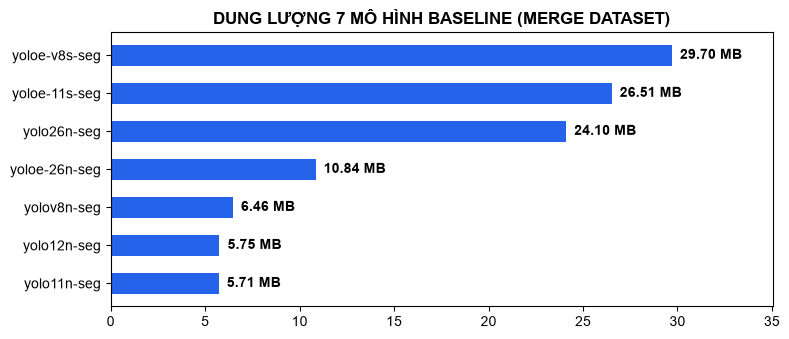

In [59]:
# 1. Lọc đúng 7 mô hình merge và tạo từ điển đường dẫn
df_merge = df_catalog[df_catalog["Original Task Dir"].str.contains("merge", case=False)].drop_duplicates("Architecture").sort_values("Size (MB)").reset_index(drop=True)
target_model_paths = dict(zip(df_merge["Architecture"], df_merge["Absolute Path"]))

# 2. Vẽ biểu đồ thanh ngang
plt.figure(figsize=(8, 3.5))
bars = plt.barh(df_merge["Architecture"], df_merge["Size (MB)"], color="#2563EB", height=0.55)
plt.bar_label(bars, fmt=" %.2f MB", fontweight="bold", padding=3)
plt.xlim(0, df_merge["Size (MB)"].max() * 1.18)
plt.title("DUNG LƯỢNG 7 MÔ HÌNH BASELINE (MERGE DATASET)", fontweight="bold")
plt.tight_layout()
plt.show()

### 3. Khai Báo Các Hàm Tiền Xử Lý, Đọc Nhãn & Vẽ Trực Quan (Overlay Polygon Mask)


In [60]:
def load_models(model_dict, device="cpu"):
    loaded = {}
    for name, path in model_dict.items():
        try:
            m = YOLO(path)
            loaded[name] = m
        except Exception as e:
            print(f"[Lỗi nạp] {name}: {e}")
    return loaded

def read_ground_truth_polygons(label_path, img_w, img_h):
    polygons = []
    if not os.path.exists(label_path):
        return polygons
    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                coords = [float(x) for x in parts[1:]]
                pts = []
                for i in range(0, len(coords), 2):
                    px = int(coords[i] * img_w)
                    py = int(coords[i+1] * img_h)
                    pts.append([px, py])
                polygons.append(np.array(pts, dtype=np.int32))
    return polygons

def draw_prediction_on_image(img_rgb, result, conf_threshold=0.25):
    """Vẽ bounding box và polygon mask lên ảnh với hiệu ứng bán trong suốt."""
    vis_img = img_rgb.copy()
    h, w, _ = vis_img.shape
    mask_overlay = np.zeros_like(vis_img, dtype=np.uint8)
    
    boxes = result.boxes
    masks = result.masks
    det_info = []
    
    if boxes is not None and len(boxes) > 0:
        for i, box in enumerate(boxes):
            conf = float(box.conf[0])
            if conf < conf_threshold:
                continue
                
            xyxy = box.xyxy[0].cpu().numpy().astype(int)
            x1, y1, x2, y2 = xyxy
            
            # 1. Vẽ Bounding box xanh lá
            cv2.rectangle(vis_img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            
            # 2. Vẽ Nhãn & Confidence
            label_text = f"dial: {conf:.2f}"
            (tw, th), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 2)
            cv2.rectangle(vis_img, (x1, max(0, y1 - th - 6)), (x1 + tw + 6, y1), (0, 255, 0), -1)
            cv2.putText(vis_img, label_text, (x1 + 3, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2)
            
            # 3. Vẽ Mask đa giác nếu có
            if masks is not None and len(masks) > i:
                poly = masks.xy[i].astype(np.int32)
                if len(poly) > 0:
                    cv2.fillPoly(mask_overlay, [poly], (0, 230, 255))
                    cv2.polylines(vis_img, [poly], isClosed=True, color=(0, 180, 255), thickness=2)
                    
            det_info.append({"conf": conf, "box": [x1, y1, x2, y2]})
            
    # Trộn mặt nạ bán trong suốt (alpha = 0.35)
    cv2.addWeighted(mask_overlay, 0.35, vis_img, 0.65, 0, vis_img)
    return vis_img, det_info


### 4. Chọn Một Số Bức Ảnh Tiêu Biểu Từ `data/DataAfterHandle/water_meters`


In [61]:
# Lấy danh sách ảnh thử nghiệm
all_images = sorted(list(IMAGES_DIR.glob("*.jpg")) + list(IMAGES_DIR.glob("*.png")))
print(f"📊 Tổng số ảnh tìm thấy trong {IMAGES_DIR}: {len(all_images)} ảnh")

# Chọn 4 bức ảnh ngẫu nhiên để so sánh (hoặc bạn có thể tự chỉnh NUM_SAMPLES)
NUM_SAMPLES = 4
random.seed(42)  # Cố định seed để dễ đối chiếu
selected_images = random.sample(all_images, min(NUM_SAMPLES, len(all_images)))

print(f"\n🖼️ Đã chọn {len(selected_images)} bức ảnh để kiểm tra:")
for idx, img_p in enumerate(selected_images, 1):
    print(f"  {idx}. {img_p.name}")


📊 Tổng số ảnh tìm thấy trong /Users/mac/MeterReadAI/data/DataAfterHandle/water_meters/images: 1244 ảnh

🖼️ Đã chọn 4 bức ảnh để kiểm tra:
  1. id_1206_value_33_069.jpg
  2. id_1047_value_84_705.jpg
  3. id_388_value_14_678.jpg
  4. id_331_value_401_774.jpg


### 5. Chạy Suy Luận & So Sánh Trực Quan Giữa Tất Cả Các Mô Hình
> Mỗi ảnh sẽ được hiển thị cạnh nhau:
> - **Ảnh gốc & Ground Truth** (đường viền xanh lá chuẩn nếu có nhãn).
> - **Kết quả của 7 mô hình baseline**: `yolo11n-seg`, `yolo12n-seg`, `yolov8n-seg`, `yolo26n-seg`, `yoloe-11s-seg`, `yoloe-26n-seg`, `yoloe-v8s-seg`.
> - Thông số hiển thị: Số lượng vùng phát hiện, Độ tin cậy (Confidence) và Thời gian suy luận (Latency ms).


/var/folders/bj/4zbr51sj4fsbvtllcchl3wzc0000gn/T/ipykernel_11937/792796328.py:77: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/bj/4zbr51sj4fsbvtllcchl3wzc0000gn/T/ipykernel_11937/792796328.py:77: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) Arial.
  plt.tight_layout()
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


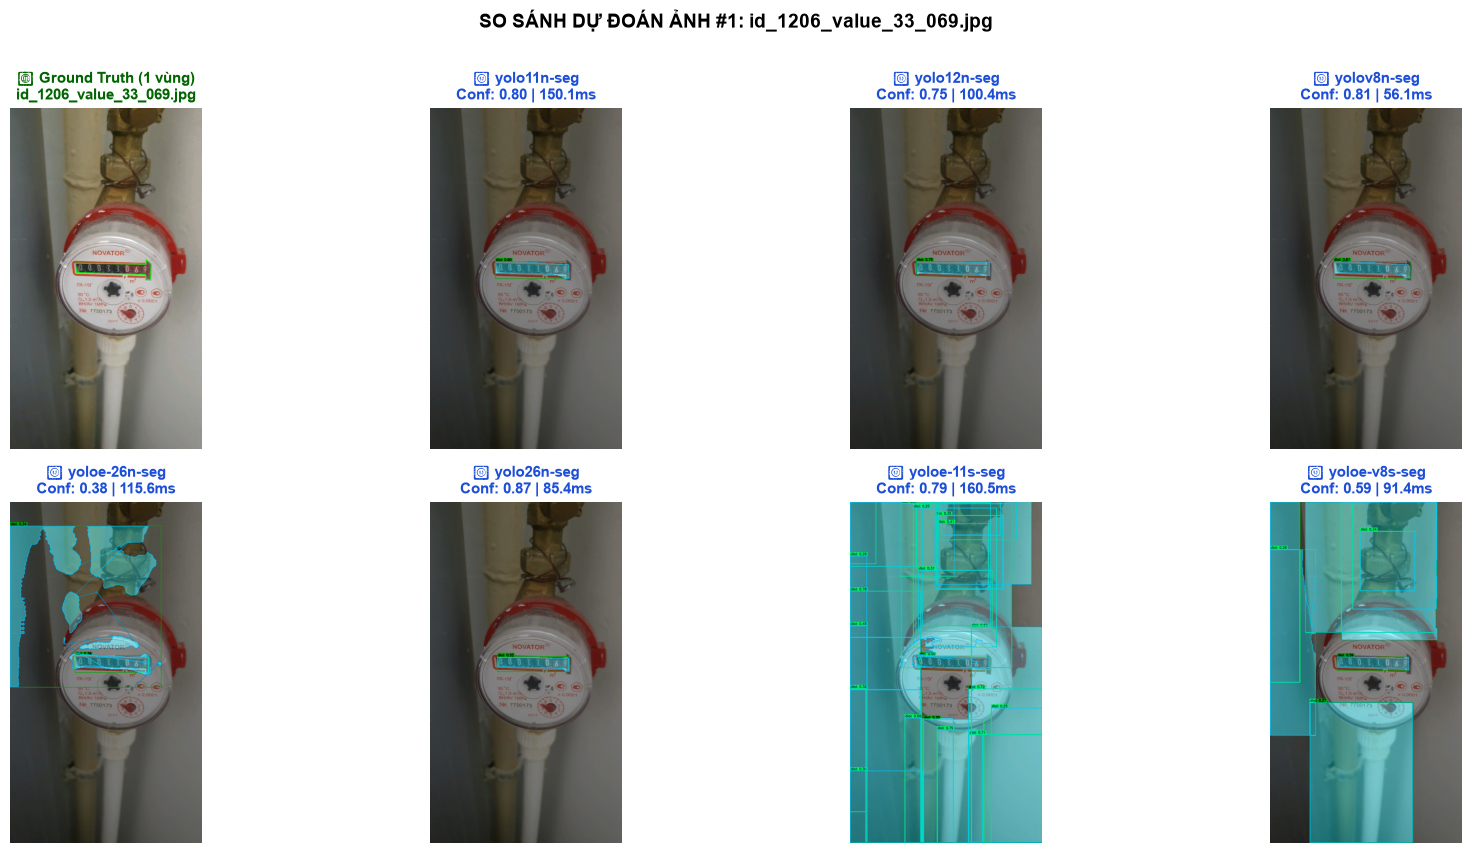

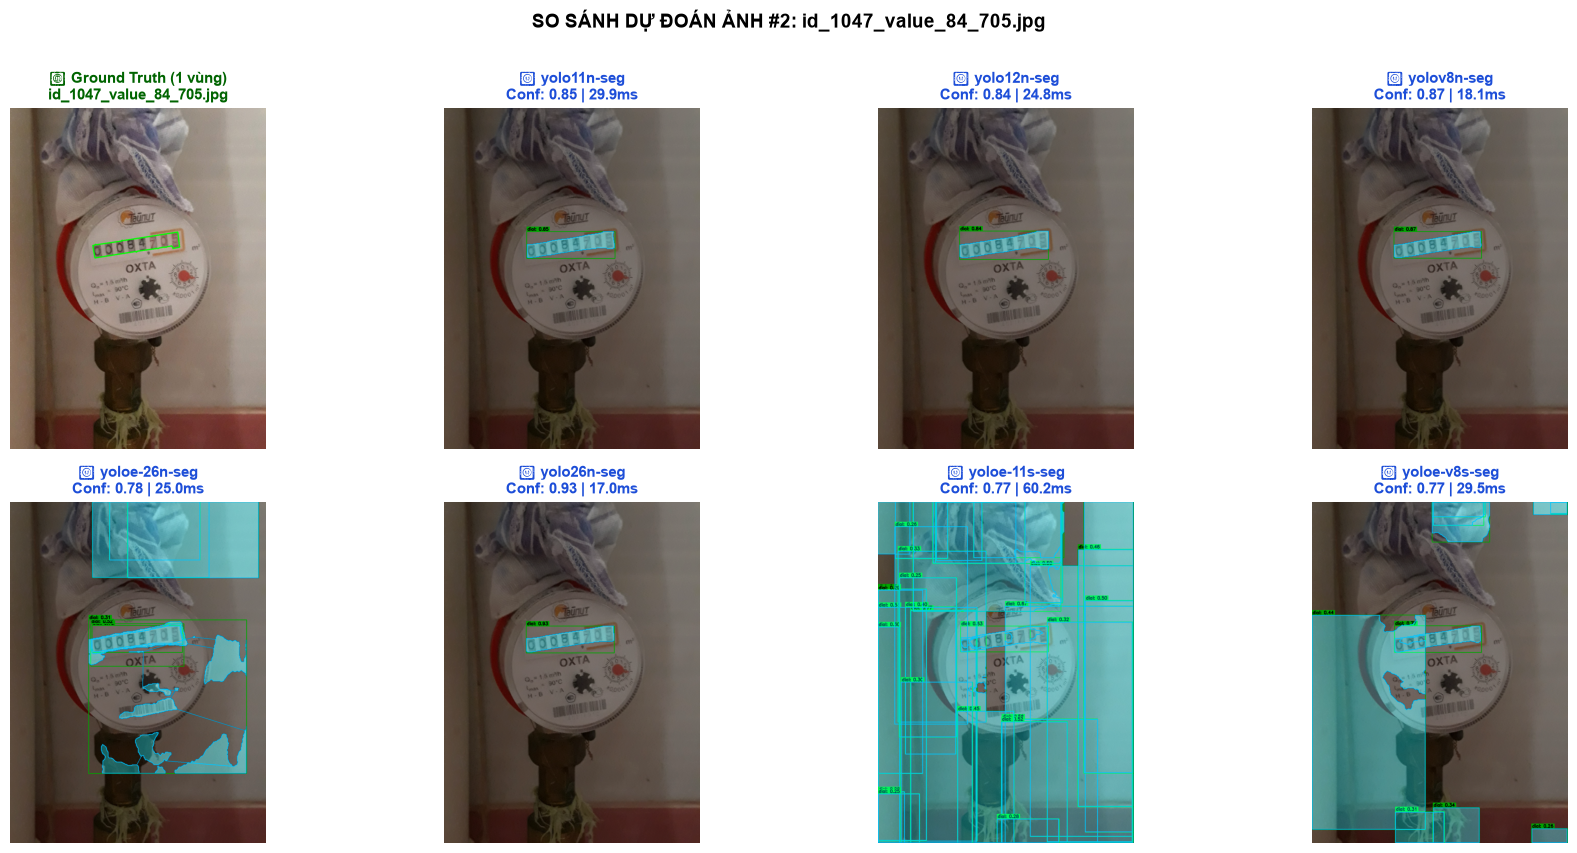

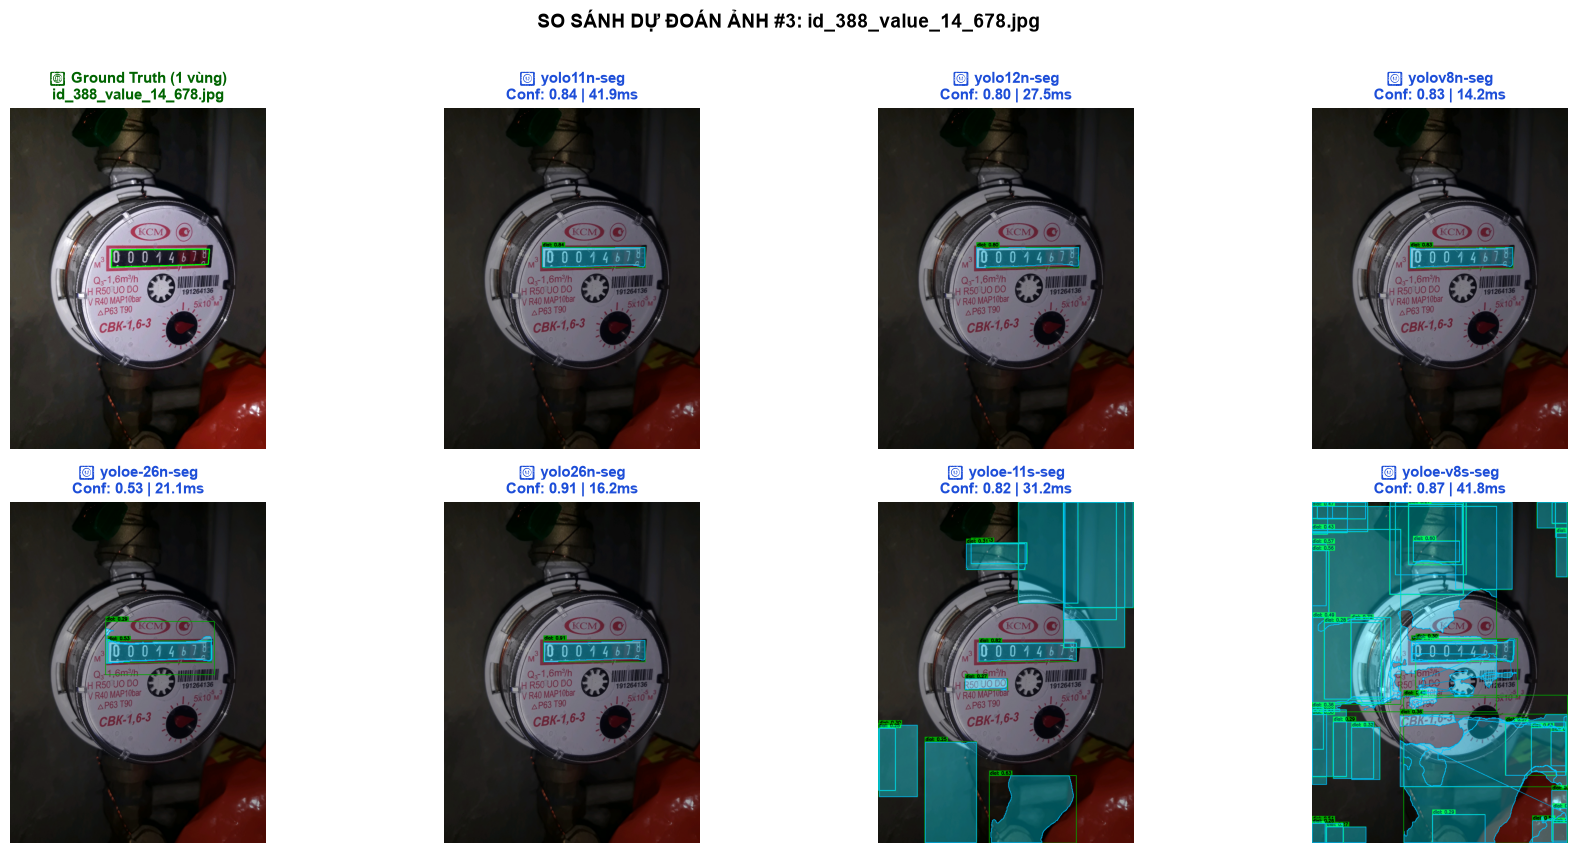

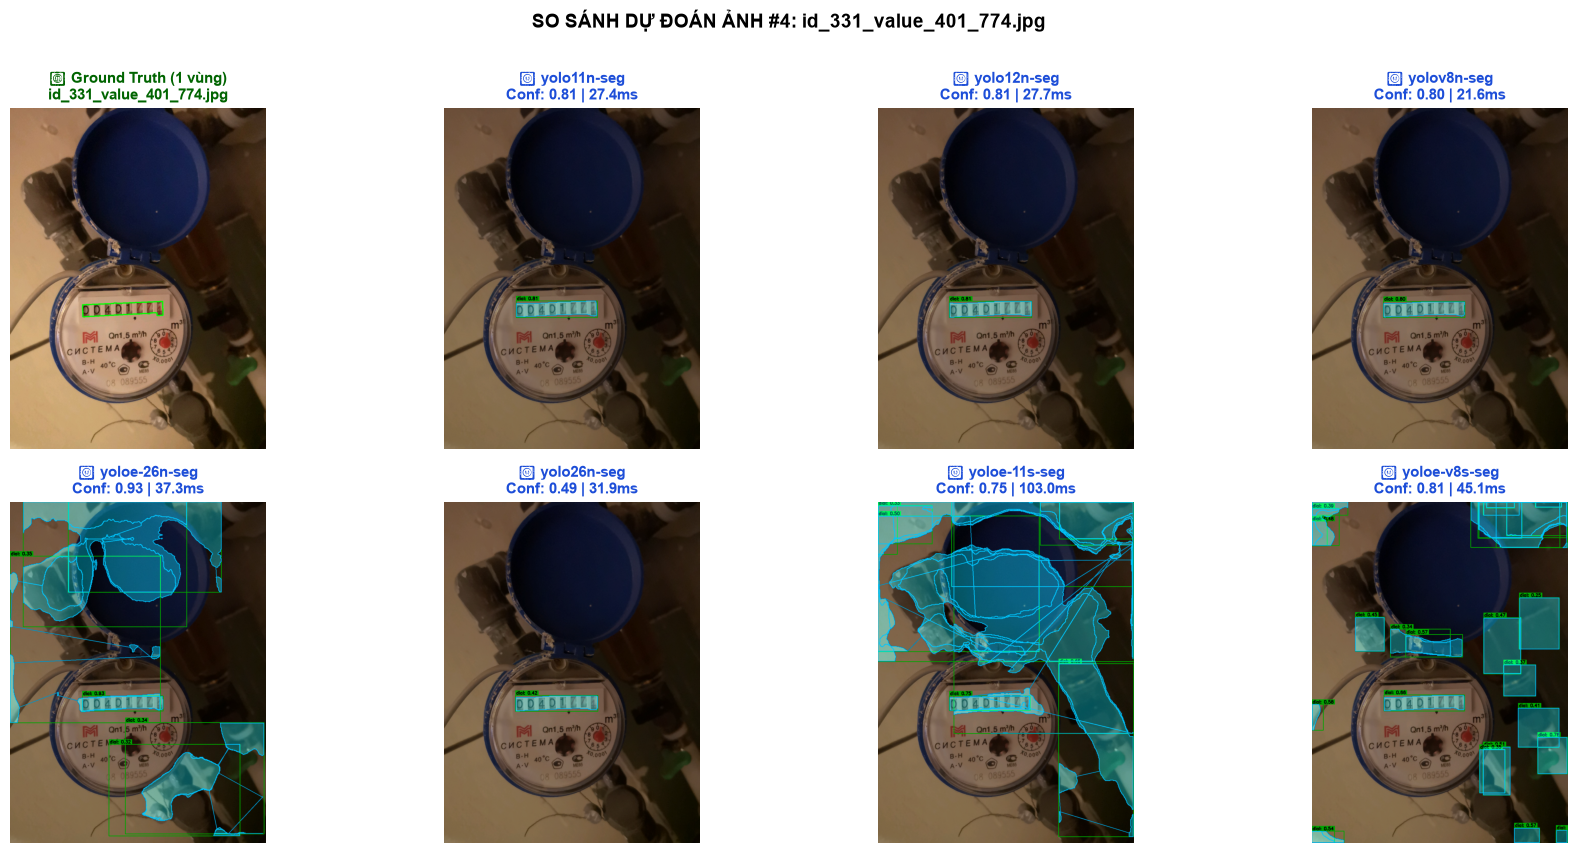

In [62]:
# Nạp toàn bộ mô hình
loaded_models = load_models(target_model_paths, device=DEVICE)

# Lưu trữ kết quả định lượng
evaluation_records = []

# Duyệt qua từng ảnh mẫu
for img_idx, img_path in enumerate(selected_images, 1):
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape
    
    # Đọc Ground Truth nếu có
    label_file = LABELS_DIR / f"{img_path.stem}.txt"
    gt_polygons = read_ground_truth_polygons(label_file, w, h)
    
    gt_img = img_rgb.copy()
    if gt_polygons:
        cv2.polylines(gt_img, gt_polygons, isClosed=True, color=(0, 255, 0), thickness=3)
        gt_title = f"Ground Truth ({len(gt_polygons)} vùng)"
    else:
        gt_title = "Ảnh Gốc (Không có nhãn)"
        
    # Tạo layout hiển thị dạng lưới: Cột 1 là Ground Truth, các cột sau là từng mô hình
    total_plots = 1 + len(loaded_models)
    cols = 4
    rows = (total_plots + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.6, rows * 4.2))
    axes = np.array(axes).reshape(-1)
    
    # 1. Subplot Ground Truth
    axes[0].imshow(gt_img)
    axes[0].set_title(f"📷 {gt_title}\n{img_path.name[:25]}", fontsize=11, fontweight="bold", color="darkgreen")
    axes[0].axis("off")
    
    plot_idx = 1
    # 2. Duyệt qua từng mô hình dự đoán
    for model_name, model in loaded_models.items():
        t0 = time.perf_counter()
        results = model(img_rgb, conf=0.25, verbose=False, device=DEVICE)
        latency_ms = (time.perf_counter() - t0) * 1000
        
        pred_img, det_info = draw_prediction_on_image(img_rgb, results[0], conf_threshold=0.25)
        
        num_dets = len(det_info)
        max_conf = max([d["conf"] for d in det_info]) if num_dets > 0 else 0.0
        
        evaluation_records.append({
            "Image": img_path.name,
            "Architecture": model_name,
            "Detections": num_dets,
            "Max Confidence": round(max_conf, 3),
            "Latency (ms)": round(latency_ms, 2)
        })
        
        # Vẽ subplot cho mô hình
        ax = axes[plot_idx]
        ax.imshow(pred_img)
        title_color = "#1D4ED8" if num_dets > 0 else "#DC2626"
        ax.set_title(
            f"🧠 {model_name}\nConf: {max_conf:.2f} | {latency_ms:.1f}ms", 
            fontsize=11, 
            fontweight="bold", 
            color=title_color
        )
        ax.axis("off")
        plot_idx += 1
        
    # Tắt các subplot trống
    for k in range(plot_idx, len(axes)):
        axes[k].axis("off")
        
    plt.suptitle(f"SO SÁNH DỰ ĐOÁN ẢNH #{img_idx}: {img_path.name}", fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()
    print("=" * 95)


### 6. Bảng Tổng Hợp Định Lượng & Biểu Đồ Hiệu Năng (Latency & Confidence)


🏆 BẢNG TỔNG HỢP HIỆU NĂNG SO SÁNH GIỮA CÁC MÔ HÌNH BASELINE:


,Architecture,Avg_Detections,Avg_Confidence,Avg_Latency_ms,Throughput (FPS),Size (MB)
0,yolov8n-seg,1.00,0.827,27.52,36.3,6.47
1,yolov8n-seg,1.00,0.827,27.52,36.3,6.47
2,yolov8n-seg,1.00,0.827,27.52,36.3,6.46
3,yolo26n-seg,1.50,0.800,37.63,26.6,6.23
4,yolo26n-seg,1.50,0.800,37.63,26.6,6.24
5,yolo26n-seg,1.50,0.800,37.63,26.6,24.10
6,yolo26n-seg,1.50,0.800,37.63,26.6,6.24
7,yolo12n-seg,1.00,0.802,45.12,22.2,5.77
8,yolo12n-seg,1.00,0.802,45.12,22.2,5.78
9,yolo12n-seg,1.00,0.802,45.12,22.2,5.77


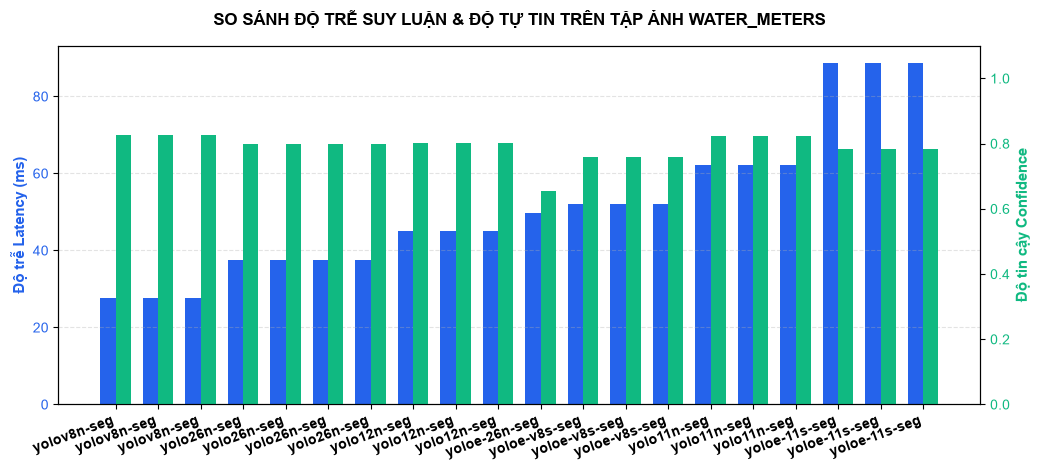

In [63]:
# Tổng hợp kết quả thành bảng DataFrame
df_eval = pd.DataFrame(evaluation_records)

# Tính giá trị trung bình theo từng kiến trúc
summary_table = df_eval.groupby("Architecture").agg(
    Avg_Detections=("Detections", "mean"),
    Avg_Confidence=("Max Confidence", "mean"),
    Avg_Latency_ms=("Latency (ms)", "mean")
).reset_index()

summary_table["Throughput (FPS)"] = (1000 / summary_table["Avg_Latency_ms"]).round(1)
summary_table["Avg_Latency_ms"] = summary_table["Avg_Latency_ms"].round(2)
summary_table["Avg_Confidence"] = summary_table["Avg_Confidence"].round(3)

# Nạp thêm dung lượng mô hình
summary_table = summary_table.merge(
    df_water_meters[["Architecture", "Size (MB)"]], 
    on="Architecture", 
    how="left"
)

# Sắp xếp theo tốc độ suy luận nhanh nhất
summary_table.sort_values(by="Avg_Latency_ms", inplace=True)
summary_table.reset_index(drop=True, inplace=True)

print("🏆 BẢNG TỔNG HỢP HIỆU NĂNG SO SÁNH GIỮA CÁC MÔ HÌNH BASELINE:")
display(summary_table)

# Vẽ biểu đồ cột đối chiếu Độ trễ (Latency) và Độ tin cậy (Confidence)
fig, ax1 = plt.subplots(figsize=(10.5, 4.8))

x = np.arange(len(summary_table))
width = 0.36

bars1 = ax1.bar(x - width/2, summary_table["Avg_Latency_ms"], width, label="Độ trễ Latency (ms) - Thấp hơn là tốt hơn", color="#2563EB")
ax1.set_ylabel("Độ trễ Latency (ms)", color="#2563EB", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(summary_table["Architecture"], rotation=20, ha="right", fontsize=10, fontweight="bold")
ax1.tick_params(axis='y', labelcolor="#2563EB")
ax1.grid(axis='y', linestyle='--', alpha=0.35)

ax2 = ax1.twinx()
bars2 = ax2.bar(x + width/2, summary_table["Avg_Confidence"], width, label="Độ tự tin Confidence (0-1) - Cao hơn là tốt hơn", color="#10B981")
ax2.set_ylabel("Độ tin cậy Confidence", color="#10B981", fontsize=11, fontweight="bold")
ax2.tick_params(axis='y', labelcolor="#10B981")
ax2.set_ylim(0, 1.1)

plt.title("SO SÁNH ĐỘ TRỄ SUY LUẬN & ĐỘ TỰ TIN TRÊN TẬP ẢNH WATER_METERS", fontsize=12, fontweight="bold", pad=15)
fig.tight_layout()
plt.show()


### 7. Thử Nghiệm Tùy Chọn Trên Một Bức Ảnh Bất Kỳ (Interactive Playground)


🔍 Đang kiểm tra ảnh: /Users/mac/MeterReadAI/data/DataAfterHandle/water_meters/images/id_1000_value_176_881.jpg


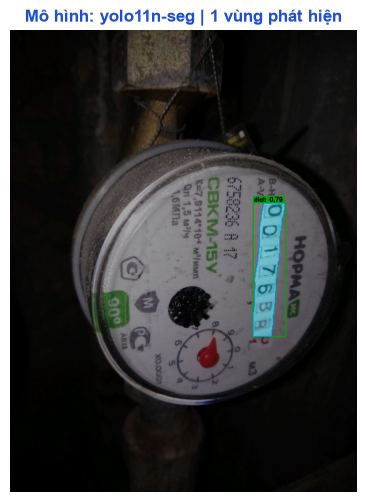

In [64]:
# Bạn có thể thay đổi đường dẫn bất kỳ ảnh nào bạn muốn kiểm tra:
CUSTOM_IMAGE_PATH = str(all_images[0])  # Mặc định lấy ảnh đầu tiên trong tập dữ liệu

if os.path.exists(CUSTOM_IMAGE_PATH):
    print(f"🔍 Đang kiểm tra ảnh: {CUSTOM_IMAGE_PATH}")
    test_img = cv2.cvtColor(cv2.imread(CUSTOM_IMAGE_PATH), cv2.COLOR_BGR2RGB)
    
    # Chọn mô hình muốn kiểm tra (ví dụ: 'yolo11n-seg', 'yolo12n-seg', ...)
    chosen_arch = "yolo11n-seg"
    
    if chosen_arch in loaded_models:
        model = loaded_models[chosen_arch]
        res = model(test_img, conf=0.25, verbose=False, device=DEVICE)
        out_img, det = draw_prediction_on_image(test_img, res[0])
        
        plt.figure(figsize=(7.5, 6))
        plt.imshow(out_img)
        plt.title(f"Mô hình: {chosen_arch} | {len(det)} vùng phát hiện", fontsize=12, fontweight="bold", color="#1D4ED8")
        plt.axis("off")
        plt.show()
    else:
        print(f"⚠️ Không tìm thấy mô hình {chosen_arch} trong danh sách nạp.")
